# 실습 2. 치료효과 추정: CausalPFN vs Kumo + DR-learner

**질문**: 혈압약을 먹으면 1년 뒤 수축기혈압이 얼마나 내려갈까요? 그리고 **누가** 약효를 크게 볼까요?

관찰 자료에서는 "치료받은 사람 vs 안 받은 사람"을 단순 비교하면 틀린 답이 나옵니다. 혈압이 높은 사람이 치료를 더 많이 받기 때문입니다(**교란**).

세 가지 방법을 비교합니다.
| 방법 | 설명 |
|---|---|
| 단순 비교 | 치료군 평균 − 비치료군 평균 (교란을 고려하지 않음) |
| CausalPFN | 인과추론용으로 미리 학습된 파운데이션 모델 (슬라이드 26~28) |
| **Kumo + DR-learner** | 표 데이터 AI(Kumo)로 필요한 예측값을 만들고 DR-learner로 결합 (슬라이드 29~31) |

이 실습은 **정답(참 치료효과)을 알고 있는 교육용 가상 환자 2,000명**으로 진행합니다. 실제 환자 자료가 아니며, 결과는 의학적 근거가 아닙니다.

**진행 방법**
- 위에서부터 셀 왼쪽의 ▶ 버튼(또는 `Ctrl+Enter`)을 눌러 **순서대로** 실행하세요. 코드는 몰라도 됩니다.
- ⚙️ 표시가 있는 셀에서만 설정을 바꿉니다. 설정을 바꾸면 그 셀부터 아래로 다시 실행하세요.
- 처음 실행할 때 "이 노트는 Google에서 작성하지 않았습니다"라는 경고가 나오면 **무시하고 계속하기**를 누르세요.
- 설치 후 "런타임을 다시 시작하라"는 안내가 나오더라도 이 실습에서는 다시 시작하지 않아도 됩니다.

In [1]:
#@title ① 준비: 필요한 도구 설치 (처음 한 번, 1~2분)
%pip install -q structured-data-models==0.2.1 causalpfn==0.1.5 koreanize-matplotlib==0.1.1

import warnings; warnings.filterwarnings("ignore")
import logging; logging.disable(logging.WARNING)
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
import koreanize_matplotlib  # 그래프에 한글 글꼴을 적용합니다
from IPython.display import display, Markdown, HTML
pd.set_option("display.precision", 2)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("✅ 준비 완료 | 계산 장치:", "GPU" if DEVICE.type == "cuda" else "CPU")
if DEVICE.type != "cuda":
    print("   CPU로도 실행됩니다. 더 빠르게 하려면 메뉴 [런타임] → [런타임 유형 변경] → [T4 GPU]를 고르세요.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 283.7/283.7 kB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 62.0 MB/s eta 0:00:00
✅ 준비 완료 | 계산 장치: GPU


In [2]:
#@title 🔧 도구 함수 불러오기 (실행만 하세요)

import sdm
from sklearn.metrics import mean_absolute_error

SEED = 2026
_KUMO = None


def is_categorical(series, name):
    """문자 열과 성별(sex)은 범주형으로, 나머지 숫자 열은 연속형으로 다룹니다."""
    return name == "sex" or not pd.api.types.is_numeric_dtype(series)


def _kumo_output(x_context, y_context, x_query):
    global _KUMO
    if _KUMO is None:
        print("Kumo 모델을 내려받는 중입니다(처음 한 번만, 약 30초)...")
        _KUMO = sdm.models.KumoTabular(task="regression", size="small", device=DEVICE)
    stypes = {c: ("categorical" if is_categorical(x_context[c], c) else "numerical") for c in x_context.columns}
    context = sdm.TableTensor.from_pandas(x_context, stypes=stypes, device=DEVICE)
    target = sdm.TableTensor.from_pandas(
        pd.DataFrame({"target": np.asarray(y_context, dtype=float)}), stypes={"target": "numerical"}, device=DEVICE)
    query = sdm.TableTensor.from_pandas(x_query, stypes=stypes, device=DEVICE)
    torch.manual_seed(SEED)
    # GPU에서도 float32로 계산해 CPU 결과와 최대한 같게 합니다.
    with torch.inference_mode():
        return _KUMO(x_context=context, y_context=target, x_query=query, num_estimators=4)


def kumo_predict(x_context, y_context, x_query):
    """Kumo는 학습하지 않습니다. 예시(x_context, y_context)를 보고 새 환자(x_query)의 예측 중앙값을 냅니다."""
    out = _kumo_output(x_context, y_context, x_query)
    return out["q500"].numerical.squeeze(-1).float().cpu().numpy()


def kumo_mean(x_context, y_context, x_query):
    """예측 분포(999개 분위수)의 평균 = 조건부 평균의 근사값. 인과효과 계산에 씁니다."""
    out = _kumo_output(x_context, y_context, x_query)
    return out.numerical.float().mean(dim=-1).cpu().numpy()

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

COLUMN_NAMES = {"age": "나이", "bmi": "BMI", "baseline_sbp": "기저 수축기혈압", "diabetes": "당뇨병(1=있음)",
                "treatment": "치료(1=받음)", "followup_sbp": "1년 후 수축기혈압", "true_effect": "참 치료효과",
                "split": "구분"}
CLOSE_ENOUGH = 2  # 환자별 효과를 ±2 mmHg 안으로 맞히면 '맞혔다'고 봅니다.


def make_example_data(n=2000, seed=SEED):
    """교육용 가상 환자 자료. 참 치료효과를 알고 있으므로 각 방법이 얼마나 맞혔는지 채점할 수 있습니다."""
    rng = np.random.default_rng(seed)
    age = rng.uniform(40, 80, n)
    sbp = rng.uniform(120, 180, n)
    bmi = rng.uniform(18, 35, n)
    diabetes = rng.binomial(1, 0.3, n)
    # 혈압이 높을수록, 당뇨병이 있을수록 치료를 더 많이 받습니다(교란).
    p_treat = np.clip(1 / (1 + np.exp(-((sbp - 150) / 8 + 0.7 * diabetes))), 0.05, 0.95)
    # 참 효과: 혈압 150 이상이면 -16 mmHg, 미만이면 -3 mmHg. 당뇨병이 있으면 4 mmHg 더 내려갑니다.
    true_effect = np.where(sbp >= 150, -16.0, -3.0) - 4.0 * diabetes
    untreated = 20 + 0.8 * sbp + 6 * np.sin((age - 60) / 5) + 0.06 * (bmi - 25) ** 2 + 4 * diabetes + rng.normal(0, 6, n)
    treatment = rng.binomial(1, p_treat)
    df = pd.DataFrame({"age": age, "bmi": bmi, "baseline_sbp": sbp, "diabetes": diabetes, "treatment": treatment,
                       "followup_sbp": untreated + treatment * true_effect, "true_effect": true_effect})
    train_idx, _ = train_test_split(np.arange(n), test_size=0.2, random_state=seed, stratify=treatment)
    df["split"] = np.where(np.isin(np.arange(n), train_idx), "train", "test")
    return df


def load_my_data(path, treatment, outcome, covariates, true_effect):
    df = pd.read_csv(path)
    needed = [treatment, outcome] + covariates + ([true_effect] if true_effect else [])
    missing = [c for c in needed if c not in df.columns]
    if missing:
        raise ValueError(f"CSV에 없는 열 이름입니다: {missing}. CSV에 있는 열: {list(df.columns)}")
    if not set(df[treatment].dropna().unique()) <= {0, 1}:
        raise ValueError(f"치료 열 '{treatment}'은(는) 0(안 받음) 또는 1(받음)이어야 합니다.")
    df = df.dropna(subset=[treatment, outcome] + covariates).reset_index(drop=True)
    out = df[covariates].copy()
    out["treatment"] = df[treatment].astype(int)
    out["followup_sbp"] = df[outcome].astype(float)
    out["true_effect"] = df[true_effect].astype(float) if true_effect else np.nan
    if "split" in df.columns:
        out["split"] = df["split"]
    else:
        train_idx, _ = train_test_split(np.arange(len(df)), test_size=0.2, random_state=SEED, stratify=out["treatment"])
        out["split"] = np.where(np.isin(np.arange(len(df)), train_idx), "train", "test")
    return out


def naive_difference(y, t):
    """단순 비교: 치료받은 사람의 평균 - 치료받지 않은 사람의 평균."""
    return y[t == 1].mean() - y[t == 0].mean()


def causalpfn_effects(x_train, t, y, x_test):
    """CausalPFN: 인과추론용으로 미리 학습된 파운데이션 모델이 환자별 효과를 바로 출력합니다."""
    from causalpfn import CATEEstimator
    estimator = CATEEstimator(device=DEVICE.type)
    estimator.fit(x_train.to_numpy(np.float32), t.astype(np.float32), y.astype(np.float32))
    return estimator.estimate_cate(x_test.to_numpy(np.float32))


def kumo_dr_learner_effects(x_train, t, y, x_test):
    """Kumo + DR-learner (슬라이드 30~31)."""
    m0, m1, e = np.zeros(len(t)), np.zeros(len(t)), np.zeros(len(t))
    folds = StratifiedKFold(n_splits=2, shuffle=True, random_state=SEED)
    for fit, held_out in folds.split(x_train, t):
        # 1단계: 다른 절반의 환자만 보고 Kumo로 m0(치료 안 받을 때 결과), m1(받을 때 결과)을,
        #        로지스틱회귀로 e(치료받을 확률)를 예측합니다. (교차 적합)
        control, treated = fit[t[fit] == 0], fit[t[fit] == 1]
        m0[held_out] = kumo_mean(x_train.iloc[control], y[control], x_train.iloc[held_out])
        m1[held_out] = kumo_mean(x_train.iloc[treated], y[treated], x_train.iloc[held_out])
        ps = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(x_train.iloc[fit], t[fit])
        e[held_out] = ps.predict_proba(x_train.iloc[held_out])[:, 1]
    e = np.clip(e, 0.05, 0.95)  # 극단적인 가중치를 막는 수치적 조치
    # 2단계: 관측된 결과와 예측의 차이로 보정한 'DR 보정값'을 환자마다 계산합니다.
    dr_value = m1 - m0 + t * (y - m1) / e - (1 - t) * (y - m0) / (1 - e)
    # 3단계: Kumo가 보정값을 예측하도록 해서 새 환자의 효과를 얻습니다.
    return kumo_mean(x_train, dr_value, x_test)


def score_methods(estimates, true_effect):
    rows = []
    has_truth = np.isfinite(true_effect).all()
    for name, est in estimates.items():
        est = np.broadcast_to(np.asarray(est, dtype=float), true_effect.shape)
        row = {"방법": name, "평균 효과 추정(mmHg)": est.mean()}
        if has_truth:
            row["평균 효과 오차"] = abs(est.mean() - true_effect.mean())
            row["환자별 효과 오차(PEHE)"] = np.sqrt(np.mean((est - true_effect) ** 2))
            row[f"±{CLOSE_ENOUGH} mmHg 안으로 맞힌 환자"] = f"{np.mean(np.abs(est - true_effect) <= CLOSE_ENOUGH):.0%}"
        rows.append(row)
    if has_truth:
        rows.append({"방법": "정답(참 효과)", "평균 효과 추정(mmHg)": true_effect.mean()})
    return pd.DataFrame(rows).round(2)


def plot_effects(estimates, test, true_effect):
    names = [n for n in estimates if n != "단순 비교"]
    fig, axes = plt.subplots(1, len(names), figsize=(6 * len(names), 4.6), sharey=True)
    x = test["baseline_sbp"].to_numpy() if "baseline_sbp" in test else np.arange(len(test))
    color = test["diabetes"].to_numpy() if "diabetes" in test else np.zeros(len(test))
    for ax, name in zip(np.atleast_1d(axes), names):
        ax.scatter(x[color == 0], estimates[name][color == 0], s=14, alpha=0.6, label="추정: 당뇨병 없음")
        ax.scatter(x[color == 1], estimates[name][color == 1], s=14, alpha=0.6, label="추정: 당뇨병 있음")
        if np.isfinite(true_effect).all() and "baseline_sbp" in test:
            grid = np.linspace(x.min(), x.max(), 400)
            ax.plot(grid, np.where(grid >= 150, -16, -3), "k-", lw=2.2, label="정답: 당뇨병 없음")
            ax.plot(grid, np.where(grid >= 150, -20, -7), "k--", lw=2.2, label="정답: 당뇨병 있음")
        ax.axhline(0, color="grey", lw=0.8)
        ax.set(title=name, xlabel="기저 수축기혈압(mmHg)" if "baseline_sbp" in test else "환자 번호",
               ylabel="환자별 치료효과 추정(mmHg)")
        ax.legend(fontsize=8, loc="lower left")
    fig.suptitle("환자별 치료효과: 점이 검은 선(정답)을 따라갈수록 정확합니다")
    fig.tight_layout()
    plt.show()

print("✅ 도구 함수 준비 완료")

✅ 도구 함수 준비 완료


## ② 데이터 보기

가상 환자 2,000명은 다음 규칙으로 만들었습니다. 정답을 알기 때문에 각 방법을 채점할 수 있습니다.
- 환자 특성: 나이, BMI, 기저 수축기혈압(120~180), 당뇨병 여부(30%)
- **누가 치료를 받나**: 혈압이 높을수록, 당뇨병이 있을수록 치료를 더 많이 받습니다 → 교란
- **참 치료효과**: 기저 혈압이 **150 이상이면 −16 mmHg**, 미만이면 −3 mmHg. 당뇨병이 있으면 4 mmHg 더 내려갑니다.
  → 약효가 큰 환자(고혈압 환자)를 골라내는 것이 중요합니다.
- 학습 1,600명으로 추정하고, 평가 400명에서 채점합니다.

> **내 데이터로 해 보기**: 한 행이 한 사람이고 `치료(0/1)`, `결과(숫자)`, `환자 특성` 열이 있으면 됩니다. 실제 자료에는 참 효과가 없으므로 채점 대신 추정값만 보여 줍니다. 결과를 믿으려면 관찰하지 못한 교란이 없다는 등 인과추론의 가정이 필요합니다.

In [3]:
#@title ⚙️ ② 데이터 고르기
#@markdown **기본 예제**(가상 환자 2,000명)를 쓰려면 그대로 실행하세요.
USE_MY_DATA = False  #@param {type:"boolean"}
#@markdown ---
#@markdown **내 데이터를 쓸 때만** 채우세요. 먼저 왼쪽 📁(파일) 창에 CSV를 올립니다.
MY_CSV_FILE = "my_data.csv"  #@param {type:"string"}
TREATMENT_COLUMN = "treatment"  #@param {type:"string"}
OUTCOME_COLUMN = "outcome"  #@param {type:"string"}
#@markdown 환자 특성(교란변수) 열 이름을 쉼표로 구분해 적으세요.
COVARIATE_COLUMNS = "age, bmi"  #@param {type:"string"}
#@markdown 참 효과 열(가상 자료에만 있음). 없으면 비워 두세요.
TRUE_EFFECT_COLUMN = ""  #@param {type:"string"}

if USE_MY_DATA:
    MY_COVARIATES = [c.strip() for c in COVARIATE_COLUMNS.split(",") if c.strip()]
    data = load_my_data(MY_CSV_FILE, TREATMENT_COLUMN, OUTCOME_COLUMN, MY_COVARIATES, TRUE_EFFECT_COLUMN.strip())
    print(f"내 데이터: {len(data)}명")
else:
    data = make_example_data()
    print("기본 예제: 교육용 가상 환자 2,000명")
    high = data["baseline_sbp"] >= 150
    print(f"치료받은 비율 → 기저 혈압 150 이상: {data.loc[high, 'treatment'].mean():.0%} / 150 미만: {data.loc[~high, 'treatment'].mean():.0%}  (교란이 있다는 뜻)")
print("나누기: 학습", (data["split"] == "train").sum(), "명 / 평가", (data["split"] == "test").sum(), "명")
display(data.head().rename(columns=COLUMN_NAMES).round(1))

기본 예제: 교육용 가상 환자 2,000명
치료받은 비율 → 기저 혈압 150 이상: 81% / 150 미만: 21%  (교란이 있다는 뜻)
나누기: 학습 1600 명 / 평가 400 명


,나이,BMI,기저 수축기혈압,당뇨병(1=있음),치료(1=받음),1년 후 수축기혈압,참 치료효과,구분
0,47.2,32.5,158.9,0,0,139.0,-16.0,train
1,65.6,23.6,178.9,0,1,157.1,-16.0,train
2,58.7,34.2,131.6,0,1,118.3,-3.0,train
3,54.8,18.4,177.9,1,1,146.0,-20.0,test
4,54.2,31.2,177.0,0,1,136.6,-16.0,train


In [4]:
#@title ⚙️ ③ 모델에게 알려 줄 환자 특성 고르기 (기본 예제에서만 적용)
#@markdown 기저 수축기혈압은 **치료 여부와 결과에 모두 영향을 주는 교란변수**입니다.
INCLUDE_BASELINE_SBP = True  #@param {type:"boolean"}

## ③ 세 방법으로 치료효과 추정하기

Kumo + DR-learner는 세 단계로 진행합니다(코드 셀의 `kumo_dr_learner_effects` 참고).
1. Kumo로 "치료를 안 받았다면 / 받았다면"의 1년 후 혈압을, 로지스틱회귀로 "치료받을 확률"을 예측합니다. 환자 자신의 결과를 보지 않도록 절반씩 나누어 예측합니다(교차 적합).
2. 실제 결과와 예측의 차이로 보정한 값(DR 보정값)을 만듭니다. 결과 예측이나 치료 확률 중 하나가 조금 틀려도 버티도록 설계된 방식입니다.
3. Kumo가 이 보정값을 예측하게 해서 **새 환자 한 명 한 명의 효과**를 얻습니다.

GPU에서는 1분 안팎, CPU에서는 몇 분 걸릴 수 있습니다.

In [5]:
# ③ 추정 실행
if USE_MY_DATA:
    covariates = MY_COVARIATES
else:
    covariates = ["age", "bmi"] + (["baseline_sbp"] if INCLUDE_BASELINE_SBP else []) + ["diabetes"]
train, test = data[data["split"] == "train"], data[data["split"] == "test"]
x_train, x_test = train[covariates].astype(float), test[covariates].astype(float)
t, y = train["treatment"].to_numpy(), train["followup_sbp"].to_numpy()

print("모델이 보는 환자 특성:", ", ".join(COLUMN_NAMES.get(c, c) for c in covariates))
estimates = {"단순 비교": naive_difference(y, t)}
print("CausalPFN 실행 중...")
estimates["CausalPFN"] = causalpfn_effects(x_train, t, y, x_test)
print("Kumo + DR-learner 실행 중...")
estimates["Kumo + DR-learner"] = kumo_dr_learner_effects(x_train, t, y, x_test)
print("✅ 추정 완료")

모델이 보는 환자 특성: 나이, BMI, 기저 수축기혈압, 당뇨병(1=있음)
CausalPFN 실행 중...


causalpfn_v0.pt: reconstructing file:   0%|          |  0.00B / 75.4MB            

causalpfn_v0.pt: downloading bytes:           |  0.00B            

Kumo + DR-learner 실행 중...
Kumo 모델을 내려받는 중입니다(처음 한 번만, 약 30초)...


config.json:   0%|          | 0.00/423 [00:00<?, ?B/s]

small/regressor.pt: reconstructing file:   0%|          |  0.00B /  114MB            

small/regressor.pt: downloading bytes:           |  0.00B            

✅ 추정 완료


## ④ 결과 보기

- **평균 효과 오차**: 평가 환자 전체의 평균 효과를 얼마나 맞혔나 (작을수록 좋음)
- **환자별 효과 오차(PEHE)**: 환자 한 명 한 명의 효과를 평균적으로 얼마나 틀렸나 (작을수록 좋음)
- **±2 mmHg 안으로 맞힌 환자**: 환자별 효과를 정답과 2 mmHg 이내로 맞힌 환자의 비율 (클수록 좋음)

음수는 치료로 혈압이 **내려간다**는 뜻입니다.

,방법,평균 효과 추정(mmHg),평균 효과 오차,환자별 효과 오차(PEHE),±2 mmHg 안으로 맞힌 환자
0,단순 비교,4.29,14.96,16.42,0%
1,CausalPFN,-10.83,0.16,2.51,60%
2,Kumo + DR-learner,-9.94,0.73,1.57,85%
3,정답(참 효과),-10.66,NaN,NaN,NaN


**해석**: 단순 비교는 평균 효과를 **15.0 mmHg**나 틀렸습니다(교란 때문). 두 AI 방법은 평균 효과를 비슷하게 맞혔습니다(오차 CausalPFN 0.16, Kumo + DR-learner 0.73 mmHg).

차이는 **환자 한 명 한 명의 효과**에서 납니다. 환자별 효과 오차는 CausalPFN **2.51**, Kumo + DR-learner **1.57** mmHg이고, ±2 mmHg 안으로 맞힌 환자는 CausalPFN **60%**, Kumo + DR-learner **85%**입니다. → **Kumo + DR-learner가 누가 약효를 크게 보는지 더 정확하게 찾았습니다.**

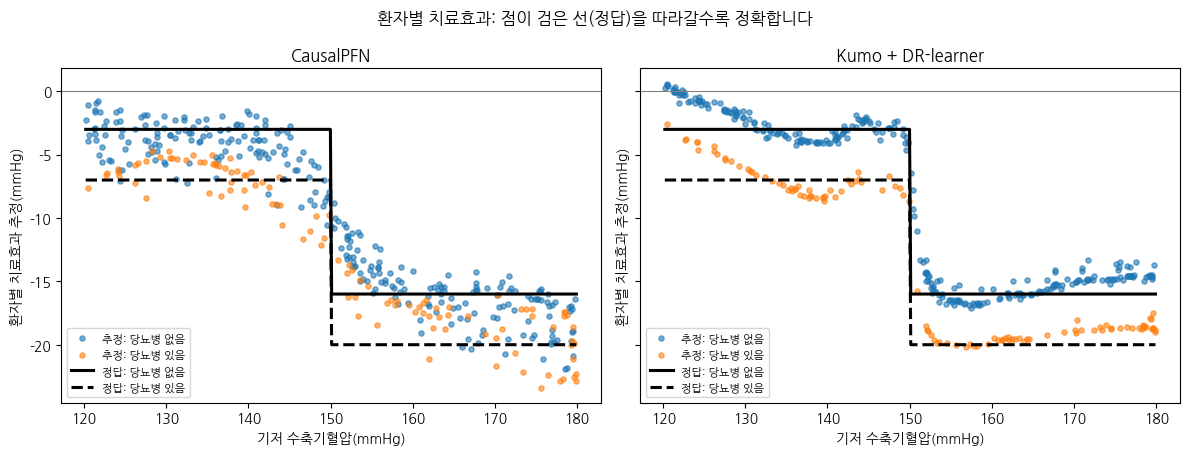

In [6]:
# ④ 결과 표와 그림
true_effect = test["true_effect"].to_numpy(dtype=float)
table = score_methods(estimates, true_effect)
display(table)

if np.isfinite(true_effect).all():
    tb = table.set_index("방법")
    close = f"±{CLOSE_ENOUGH} mmHg 안으로 맞힌 환자"
    pfn, kdr = tb.loc["CausalPFN"], tb.loc["Kumo + DR-learner"]
    display(Markdown(
        f"**해석**: 단순 비교는 평균 효과를 **{tb.loc['단순 비교', '평균 효과 오차']:.1f} mmHg**나 틀렸습니다(교란 때문). "
        f"두 AI 방법은 평균 효과를 비슷하게 맞혔습니다(오차 CausalPFN {pfn['평균 효과 오차']:.2f}, Kumo + DR-learner {kdr['평균 효과 오차']:.2f} mmHg).\n\n"
        f"차이는 **환자 한 명 한 명의 효과**에서 납니다. 환자별 효과 오차는 CausalPFN **{pfn['환자별 효과 오차(PEHE)']:.2f}**, "
        f"Kumo + DR-learner **{kdr['환자별 효과 오차(PEHE)']:.2f}** mmHg이고, ±{CLOSE_ENOUGH} mmHg 안으로 맞힌 환자는 "
        f"CausalPFN **{pfn[close]}**, Kumo + DR-learner **{kdr[close]}**입니다. "
        + ("→ **Kumo + DR-learner가 누가 약효를 크게 보는지 더 정확하게 찾았습니다.**"
           if kdr["환자별 효과 오차(PEHE)"] < pfn["환자별 효과 오차(PEHE)"] else "→ 이번 설정에서는 CausalPFN이 더 정확했습니다.")))
    plot_effects(estimates, test, true_effect)
else:
    display(Markdown("참 효과가 없는 실제 자료이므로 평균 효과 추정값만 비교합니다."))

## ⑤ 바꿔 보기

1. ⚙️ ③ 셀에서 `INCLUDE_BASELINE_SBP`의 체크를 **해제**하고 ③부터 다시 실행하세요.
   기저 혈압(교란변수)을 모델이 모르면 어떻게 될까요?
2. 그림에서 두 방법의 점이 정답선(검은 계단 모양)을 얼마나 따라가는지 비교해 보세요.

> **생각해 볼 점**
> - 평균 효과만 보면 두 AI 방법 모두 정답에 가깝습니다. 차이는 **환자별 효과**에서 납니다. Kumo + DR-learner는 "혈압 150 이상에서 약효가 크다"는 계단 모양을 더 잘 찾아냅니다.
> - 교란변수를 빼면 **어떤 AI도 정답을 복구하지 못합니다.** 좋은 예측 모델이 관찰하지 않은 교란을 해결해 주지는 않습니다.
> - 제작 과정에서 같은 규칙으로 자료를 새로 만들어 반복 확인했습니다. 환자별 효과 오차는 환자 2,000명일 때 8번 중 8번, 1,000명일 때 8번 중 7번 Kumo + DR-learner가 더 작았습니다. 평균 효과 오차는 두 방법이 비슷했습니다.